# 4. Explainable Fuzzy Classifier (10%), continued: pyFUME model
This notebook continues section 4 of `emotion_detection_group11.ipynb`. Sections 4.1–4.2
there extract dlib landmarks and seven geometric features for the 980 frontal KDEF images
and write them to `results/task4/geometric_features.csv`. Run them first.

**Kernel: `emotion-fuzzy`** (`conda env create -f environment-fuzzy.yml`). pyFUME 0.3.4
pins numpy 1.24.4, pandas 1.5.3 and scipy 1.10.1, which conflict with the main environment.
This is why the fuzzy model lives in its own notebook. The assignment recommends this setup.

### 4.3 Setup
We reuse the supplied 56/14 identity split exactly as stored in the feature file. Every
image of an identity, from both photo sessions, is either in training or in test.

In [1]:
from pathlib import Path
from time import perf_counter
import contextlib
import importlib.metadata
import io
import json
import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyfume import pyFUME
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

T4_ROOT = Path.cwd()
assert (T4_ROOT / 'task4_fuzzy.ipynb').exists(), 'Run from the repository folder.'
T4_OUT = T4_ROOT / 'results' / 'task4'
T4_MODELS = T4_ROOT / 'models' / 'task4'
T4_MODELS.mkdir(parents=True, exist_ok=True)
T4_SEED = 42
T4_NAMES = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
T4_LABELS = np.arange(7)
T4_FEATURES = ['mouth_open', 'mouth_width', 'lip_corner_lift', 'eye_open',
               'inner_brow_raise', 'brow_slant', 'inner_brow_gap']

# Features come from section 4.2 of emotion_detection_group11.ipynb (main environment).
t4_data = pd.read_csv(T4_OUT / 'geometric_features.csv')
assert list(t4_data.columns[-len(T4_FEATURES):]) == T4_FEATURES
assert len(t4_data) == 980 and t4_data.groupby('subject')['split'].nunique().max() == 1
t4_train = t4_data.loc[t4_data.split == 'train'].reset_index(drop=True)
t4_test = t4_data.loc[t4_data.split == 'test'].reset_index(drop=True)
X_train, y_train, g_train = t4_train[T4_FEATURES].to_numpy(), t4_train.label.to_numpy(), t4_train.subject.to_numpy()
X_test, y_test = t4_test[T4_FEATURES].to_numpy(), t4_test.label.to_numpy()
print(f'Train: {len(t4_train)} images / {t4_train.subject.nunique()} identities | '
      f'Test: {len(t4_test)} images / {t4_test.subject.nunique()} identities')
print('pyFUME:', importlib.metadata.version('pyfume'), '| Python:', sys.version.split()[0])

Train: 784 images / 56 identities | Test: 196 images / 14 identities
pyFUME: 0.3.4 | Python: 3.11.17


### 4.4 One-vs-rest Takagi–Sugeno models
pyFUME builds **Takagi–Sugeno (TS)** fuzzy models. A TS model produces a single numeric
output, so it cannot directly output one of seven classes. We therefore train **one model
per emotion**, with target 1 for that emotion and 0 for all others, and predict the emotion
whose model gives the highest output.

How pyFUME builds each model:
1. **Fuzzy c-means clustering** on the min-max-normalised features *together with the
   target*. Each cluster becomes one rule.
2. **Antecedents:** each cluster is projected onto every feature as a Gaussian membership
   function. A rule then reads: IF `mouth_open` is *set₁* AND … AND `inner_brow_gap` is *set₁*.
3. **Consequents:** each rule outputs a constant (*zero-order*) or a linear function of
   the features (*first-order*), estimated by least squares weighted by the rule's firing strength.

We change three pyFUME defaults:
- `percentage_training=1.0`: pyFUME's own hold-out split shuffles rows randomly. That would
  put the same identity on both sides of the split, so we give it training rows only and
  split by identity ourselves.
- `setnes_threshold=1.0`: the default rule simplification can delete every fuzzy set of a
  feature, after which simpful refuses to build the model. We keep all sets, so every rule
  uses all seven features.
- `np.random.seed`: pyFUME's shuffle and the c-means initialisation use NumPy's global
  random generator, so we seed it before every fit for reproducibility.

In [2]:
def fit_fuzzy_ovr(X, y, nr_clus, model_order, seed=T4_SEED):
    """Fit one Takagi-Sugeno model per emotion (target 1 = this emotion, 0 = any other)."""
    models = []
    for label in T4_LABELS:
        frame = pd.DataFrame(X, columns=T4_FEATURES)
        frame['target'] = (y == label).astype(float)
        np.random.seed(seed)  # pyFUME's row shuffle and FCM initialisation use the global RNG
        with contextlib.redirect_stdout(io.StringIO()):  # pyFUME prints variable names per fit
            models.append(pyFUME(dataframe=frame, nr_clus=nr_clus, model_order=model_order,
                                 percentage_training=1.0,  # we split by identity ourselves
                                 normalize='minmax', setnes_threshold=1.0,
                                 save_simpful_code=False))
    return models

def fuzzy_scores(models, X):
    """Return an (n_samples, 7) matrix of per-emotion Takagi-Sugeno outputs."""
    with contextlib.redirect_stdout(io.StringIO()):
        return np.column_stack([model.predict_label(X) for model in models])

def fuzzy_predict(models, X):
    return fuzzy_scores(models, X).argmax(axis=1)

### 4.5 Select the rule type and the number of rules on training identities
Grid: zero- vs. first-order consequents × 2, 3 or 4 rules per emotion (14–28 rules in total).
We score each configuration with 5-fold GroupKFold on the 56 training identities, by mean
macro-F1, matching Task 2. The task is about explainability, so we do not simply take the
best mean. We pick the **fewest rules** whose mean is within one fold standard deviation of
the best. The test identities are not used here.

In [3]:
t4_cv = GroupKFold(n_splits=5)
t4_cv_rows = []
start = perf_counter()
for model_order in ['zero', 'first']:
    for nr_clus in [2, 3, 4]:
        fold_scores = []
        for fold, (fit_idx, val_idx) in enumerate(t4_cv.split(X_train, y_train, g_train)):
            assert set(g_train[fit_idx]).isdisjoint(g_train[val_idx])
            models = fit_fuzzy_ovr(X_train[fit_idx], y_train[fit_idx], nr_clus, model_order)
            pred = fuzzy_predict(models, X_train[val_idx])
            fold_scores.append({'accuracy': accuracy_score(y_train[val_idx], pred),
                                'macro_f1': f1_score(y_train[val_idx], pred, average='macro')})
        fold_scores = pd.DataFrame(fold_scores)
        t4_cv_rows.append({'model_order': model_order, 'rules_per_emotion': nr_clus,
                           'total_rules': 7 * nr_clus,
                           'accuracy_mean': fold_scores.accuracy.mean(),
                           'macro_f1_mean': fold_scores.macro_f1.mean(),
                           'macro_f1_std': fold_scores.macro_f1.std(ddof=0)})
        print(f'{model_order:5s} order, {nr_clus} rules/emotion: '
              f'macro-F1 {fold_scores.macro_f1.mean():.4f} ± {fold_scores.macro_f1.std(ddof=0):.4f}', flush=True)
t4_cv_results = pd.DataFrame(t4_cv_rows)
t4_cv_results.to_csv(T4_OUT / 'fuzzy_training_cv_results.csv', index=False)
print(f'CV elapsed: {perf_counter()-start:.0f}s')

# Prefer the fewest rules whose mean macro-F1 is within one fold SD of the best configuration.
t4_best = t4_cv_results.loc[t4_cv_results.macro_f1_mean.idxmax()]
t4_eligible = t4_cv_results.loc[t4_cv_results.macro_f1_mean >= t4_best.macro_f1_mean - t4_best.macro_f1_std]
t4_selected = t4_eligible.sort_values(['total_rules', 'macro_f1_mean'], ascending=[True, False]).iloc[0]
T4_ORDER, T4_CLUS = t4_selected.model_order, int(t4_selected.rules_per_emotion)
display(t4_cv_results.round(4))
print(f'Selected: {T4_ORDER}-order consequents, {T4_CLUS} rules per emotion ({7*T4_CLUS} rules total)')

zero  order, 2 rules/emotion: macro-F1 0.3345 ± 0.0413


zero  order, 3 rules/emotion: macro-F1 0.4147 ± 0.0241


zero  order, 4 rules/emotion: macro-F1 0.4548 ± 0.0135


first order, 2 rules/emotion: macro-F1 0.7009 ± 0.0185


first order, 3 rules/emotion: macro-F1 0.7017 ± 0.0277


first order, 4 rules/emotion: macro-F1 0.7164 ± 0.0280


CV elapsed: 61s


,model_order,rules_per_emotion,total_rules,accuracy_mean,macro_f1_mean,macro_f1_std
0,zero,2,14,0.4448,0.3345,0.0413
1,zero,3,21,0.4668,0.4147,0.0241
2,zero,4,28,0.5061,0.4548,0.0135
3,first,2,14,0.7188,0.7009,0.0185
4,first,3,21,0.7146,0.7017,0.0277
5,first,4,28,0.7261,0.7164,0.0280


Selected: first-order consequents, 2 rules per emotion (14 rules total)


### 4.6 Fit on all training identities and evaluate the test identities once
The configuration above is frozen before this cell runs. Two references put the fuzzy
model's score in context:
- **Logistic regression on the same seven features** isolates the cost of using fuzzy rules
  rather than a standard linear classifier.
- **The Task 2 HOG results** show what is given up by using seven interpretable
  measurements instead of thousands of pixel-gradient features.

In [4]:
start = perf_counter()
t4_models = fit_fuzzy_ovr(X_train, y_train, T4_CLUS, T4_ORDER)
t4_fit_seconds = perf_counter() - start
t4_test_scores = fuzzy_scores(t4_models, X_test)
t4_test_pred = t4_test_scores.argmax(axis=1)

# Reference: a standard linear classifier on the same seven features, and Task 2 (HOG pixels).
t4_reference = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=T4_SEED))
t4_reference.fit(X_train, y_train)
t4_reference_pred = t4_reference.predict(X_test)
t4_task2 = pd.read_csv(T4_ROOT / 'results/task2/test_results.csv').set_index('classifier')

def t4_metrics(name, pred):
    return {'model': name, 'accuracy': accuracy_score(y_test, pred),
            'balanced_accuracy': balanced_accuracy_score(y_test, pred),
            'macro_f1': f1_score(y_test, pred, average='macro')}

t4_results = pd.DataFrame([
    t4_metrics(f'Fuzzy TS one-vs-rest ({7*T4_CLUS} rules), 7 geometric features', t4_test_pred),
    t4_metrics('Logistic Regression, same 7 geometric features', t4_reference_pred),
    {'model': 'Task 2: HOG + Logistic Regression (selected)',
     **t4_task2.loc['Logistic Regression', ['accuracy', 'balanced_accuracy', 'macro_f1']].to_dict()},
    {'model': 'Task 2: HOG + Random Forest (best test)',
     **t4_task2.loc['Random Forest', ['accuracy', 'balanced_accuracy', 'macro_f1']].to_dict()},
])
t4_results.to_csv(T4_OUT / 'fuzzy_test_results.csv', index=False)
display(t4_results.round(4))
print(classification_report(y_test, t4_test_pred, labels=T4_LABELS, target_names=T4_NAMES, digits=3))
pd.DataFrame(classification_report(y_test, t4_test_pred, labels=T4_LABELS, target_names=T4_NAMES,
                                   output_dict=True)).T.to_csv(T4_OUT / 'fuzzy_classification_report.csv')
t4_counts = confusion_matrix(y_test, t4_test_pred, labels=T4_LABELS)
pd.DataFrame(t4_counts, index=T4_NAMES, columns=T4_NAMES).to_csv(T4_OUT / 'fuzzy_confusion_counts.csv')
t4_test.assign(predicted=t4_test_pred, predicted_emotion=[T4_NAMES[p] for p in t4_test_pred],
               **{f'score_{name}': t4_test_scores[:, i] for i, name in enumerate(T4_NAMES)}
               ).to_csv(T4_OUT / 'fuzzy_test_predictions.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, normalize, title in [(axes[0], None, 'Counts'), (axes[1], 'true', 'Row-normalised (recall)')]:
    ConfusionMatrixDisplay.from_predictions(y_test, t4_test_pred, labels=T4_LABELS, display_labels=T4_NAMES,
                                            normalize=normalize, values_format='d' if normalize is None else '.2f',
                                            cmap='Blues', colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(title)
fig.suptitle(f'Fuzzy classifier on KDEF test identities (macro-F1 {t4_results.macro_f1[0]:.3f})')
plt.tight_layout()
fig.savefig(T4_OUT / 'fuzzy_test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

,model,accuracy,balanced_accuracy,macro_f1
0,"Fuzzy TS one-vs-rest (14 rules), 7 geometric f...",0.6837,0.6837,0.6500
1,"Logistic Regression, same 7 geometric features",0.6888,0.6888,0.6687
2,Task 2: HOG + Logistic Regression (selected),0.5612,0.5612,0.5722
3,Task 2: HOG + Random Forest (best test),0.6020,0.6020,0.5887


              precision    recall  f1-score   support

       Angry      0.552     0.571     0.561        28
     Disgust      0.750     0.750     0.750        28
        Fear      0.750     0.107     0.188        28
       Happy      0.966     1.000     0.982        28
         Sad      0.533     0.571     0.552        28
    Surprise      0.614     0.964     0.750        28
     Neutral      0.719     0.821     0.767        28

    accuracy                          0.684       196
   macro avg      0.698     0.684     0.650       196
weighted avg      0.698     0.684     0.650       196



<Figure size 1300x520 with 2 Axes>

### 4.7 Read the rules back
Each emotion's model has one **prototype rule**: the cluster whose centre has the highest
target value, i.e. the typical face of that emotion. To make it readable, we label each
Gaussian set by where its centre falls among the training values of that feature:
**LOW**, **MEDIUM** or **HIGH** (training terciles). A set with σ > 1 (in normalised units)
is labelled **ANY**: its membership stays above 0.61 over the whole training range, so it
barely constrains the feature. The printed rules omit MEDIUM and ANY conditions for
readability. The model itself still evaluates every condition.

The c-means clusters are fitted with fuzzifier m = 2, so the membership functions overlap
widely. A label summarises where a set is centred, not a sharp threshold. If a model's
clusters never separate its emotion (every rule's target centre is low), it has no prototype
rule: its sets are flat and the decision is made by the linear consequents alone. This is
also the case that pyFUME's default simplification (`setnes_threshold`) cannot handle.

With first-order consequents, a rule's output also depends linearly on the features. The
coefficient heat map shows which measurements raise or lower each emotion's score. Its
values are in min-max-normalised units, so the coefficients are comparable across features.

In [5]:
# Read the rules back from the fitted models. pyFUME clusters [features, target], so each rule's
# cluster centre has a target value: the rule with the highest target describes the typical face
# of that emotion ("prototype rule"); the others describe the remaining faces.
t4_mins, t4_maxs = X_train.min(axis=0), X_train.max(axis=0)
t4_terciles = np.percentile(X_train, [100 / 3, 200 / 3], axis=0)

def t4_term(feature_index, mu, sigma):
    """Linguistic label of a Gaussian set, by where its centre falls among training values."""
    if sigma > 1.0:  # membership stays above exp(-1/2) = 0.61 over the whole training range
        return 'ANY'
    value = t4_mins[feature_index] + mu * (t4_maxs[feature_index] - t4_mins[feature_index])
    low, high = t4_terciles[:, feature_index]
    return 'LOW' if value < low else 'HIGH' if value > high else 'MEDIUM'

t4_rule_rows, t4_rule_text = [], []
for label, model in zip(T4_LABELS, t4_models):
    fis = model.FIS
    targets = fis.cluster_centers[:, -1]
    for rule in range(T4_CLUS):
        terms = {}
        for i, feature in enumerate(T4_FEATURES):
            _, (mu, sigma) = fis.antecedent_parameters[i * T4_CLUS + rule]
            terms[feature] = t4_term(i, mu, sigma)
        prototype = rule == targets.argmax()
        t4_rule_rows.append({'emotion': T4_NAMES[label], 'rule': rule + 1, 'prototype': prototype,
                             'target_centre': targets[rule], **terms,
                             **{f'coef_{f}': c for f, c in zip(T4_FEATURES, fis.consequent_parameters[rule][:-1])},
                             'intercept': fis.consequent_parameters[rule][-1]})
        if prototype:
            conditions = [f'{f} is {t}' for f, t in terms.items() if t not in ('MEDIUM', 'ANY')]
            t4_rule_text.append(f'IF {" AND ".join(conditions) or "(no LOW/HIGH conditions)"} '
                                f'THEN {T4_NAMES[label]} (prototype target {targets[rule]:.2f})')
t4_rules = pd.DataFrame(t4_rule_rows)
# A model whose rules all have a low target never isolated its emotion in a cluster; its
# antecedents are then flat and the decision rests on the linear consequents alone.
t4_no_prototype = [T4_NAMES[l] for l, m in zip(T4_LABELS, t4_models) if m.FIS.cluster_centers[:, -1].max() < 0.5]
print('Models without a prototype rule (max target centre < 0.5):', t4_no_prototype or 'none')
t4_rules.to_csv(T4_OUT / 'fuzzy_rules.csv', index=False)
(T4_OUT / 'fuzzy_rules.txt').write_text('\n'.join(t4_rule_text) + '\n')
print('Prototype rules (MEDIUM/ANY conditions omitted for readability; the model uses all of them):\n')
print('\n'.join(t4_rule_text))
display(t4_rules.loc[t4_rules.prototype, ['emotion', 'target_centre', *T4_FEATURES]]
        .set_index('emotion').round(2))

Models without a prototype rule (max target centre < 0.5): ['Neutral']
Prototype rules (MEDIUM/ANY conditions omitted for readability; the model uses all of them):

IF eye_open is LOW AND inner_brow_raise is LOW AND brow_slant is LOW AND inner_brow_gap is LOW THEN Angry (prototype target 0.84)
IF mouth_width is HIGH AND eye_open is LOW AND brow_slant is LOW AND inner_brow_gap is LOW THEN Disgust (prototype target 0.78)
IF mouth_open is HIGH AND mouth_width is HIGH AND inner_brow_raise is HIGH AND brow_slant is HIGH THEN Fear (prototype target 0.74)
IF mouth_open is HIGH AND mouth_width is HIGH AND lip_corner_lift is HIGH AND eye_open is LOW AND inner_brow_raise is HIGH AND inner_brow_gap is HIGH THEN Happy (prototype target 0.90)
IF mouth_open is LOW AND mouth_width is HIGH AND inner_brow_raise is HIGH AND brow_slant is HIGH THEN Sad (prototype target 0.78)
IF mouth_open is HIGH AND mouth_width is LOW AND lip_corner_lift is HIGH AND eye_open is HIGH AND inner_brow_raise is HIGH AND inn

,target_centre,mouth_open,mouth_width,lip_corner_lift,eye_open,inner_brow_raise,brow_slant,inner_brow_gap
emotion,,,,,,,,
Angry,0.84,MEDIUM,MEDIUM,MEDIUM,LOW,LOW,LOW,LOW
Disgust,0.78,MEDIUM,HIGH,MEDIUM,LOW,MEDIUM,LOW,LOW
Fear,0.74,HIGH,HIGH,MEDIUM,MEDIUM,HIGH,HIGH,MEDIUM
Happy,0.90,HIGH,HIGH,HIGH,LOW,HIGH,MEDIUM,HIGH
Sad,0.78,LOW,HIGH,MEDIUM,MEDIUM,HIGH,HIGH,MEDIUM
Surprise,0.86,HIGH,LOW,HIGH,HIGH,HIGH,MEDIUM,HIGH
Neutral,0.14,ANY,ANY,ANY,ANY,ANY,ANY,ANY


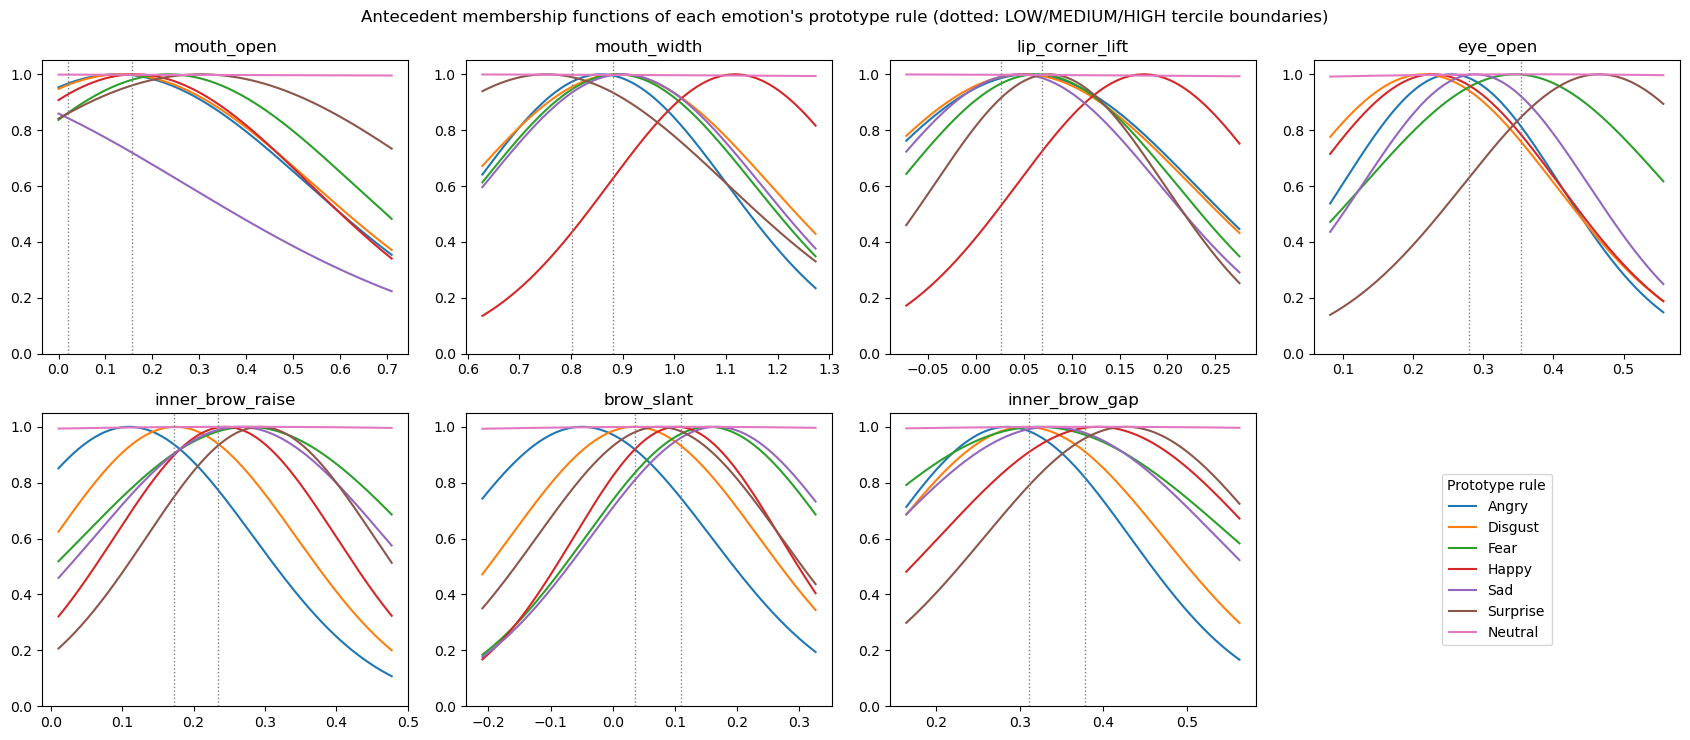

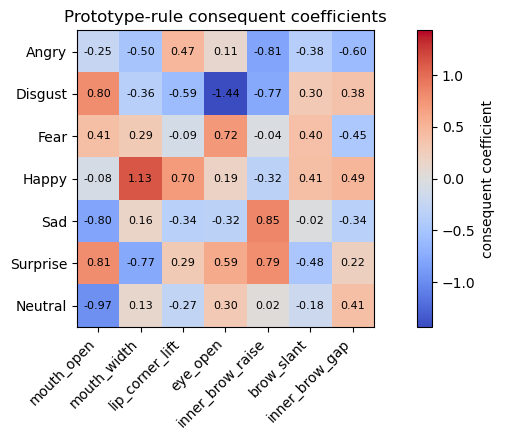

In [6]:
# Membership function of each emotion's prototype rule, drawn in original feature units.
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
colors = plt.cm.tab10(np.arange(7))
for i, (ax, feature) in enumerate(zip(axes.flat, T4_FEATURES)):
    grid = np.linspace(t4_mins[i], t4_maxs[i], 300)
    normalised = (grid - t4_mins[i]) / (t4_maxs[i] - t4_mins[i])
    for label, model in zip(T4_LABELS, t4_models):
        rule = model.FIS.cluster_centers[:, -1].argmax()
        _, (mu, sigma) = model.FIS.antecedent_parameters[i * T4_CLUS + rule]
        ax.plot(grid, np.exp(-((normalised - mu) ** 2) / (2 * sigma ** 2)), color=colors[label],
                label=T4_NAMES[label])
    for cut in t4_terciles[:, i]:
        ax.axvline(cut, color='grey', ls=':', lw=1)
    ax.set_title(feature)
    ax.set_ylim(0, 1.05)
axes.flat[-1].axis('off')
axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(), loc='center', title='Prototype rule')
fig.suptitle('Antecedent membership functions of each emotion\'s prototype rule '
             '(dotted: LOW/MEDIUM/HIGH tercile boundaries)')
plt.tight_layout()
fig.savefig(T4_OUT / 'fuzzy_prototype_mfs.png', dpi=160, bbox_inches='tight')
plt.show()

# First-order consequents: how each (min-max normalised) feature moves the emotion's score.
t4_coefs = (t4_rules.loc[t4_rules.prototype].set_index('emotion')
            [[f'coef_{f}' for f in T4_FEATURES]].rename(columns=lambda c: c[5:]))
if T4_ORDER == 'first':
    limit = np.abs(t4_coefs.to_numpy()).max()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    image = ax.imshow(t4_coefs, cmap='coolwarm', vmin=-limit, vmax=limit)
    ax.set_xticks(range(len(T4_FEATURES)), T4_FEATURES, rotation=45, ha='right')
    ax.set_yticks(range(7), t4_coefs.index)
    for (r, c), value in np.ndenumerate(t4_coefs.to_numpy()):
        ax.text(c, r, f'{value:.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(image, ax=ax, label='consequent coefficient')
    ax.set_title('Prototype-rule consequent coefficients')
    plt.tight_layout()
    fig.savefig(T4_OUT / 'fuzzy_prototype_consequents.png', dpi=160, bbox_inches='tight')
    plt.show()

### 4.8 Save the model and metadata

In [7]:
joblib.dump({'models': t4_models, 'features': T4_FEATURES, 'class_names': T4_NAMES,
             'model_order': T4_ORDER, 'rules_per_emotion': T4_CLUS,
             'feature_source': 'results/task4/geometric_features.csv (section 4.2)',
             'predict': 'argmax over the 7 one-vs-rest outputs of model.predict_label(X)'},
            T4_MODELS / 'fuzzy_ovr.pkl', compress=3)
(T4_OUT / 'fuzzy_selection.json').write_text(json.dumps({
    'model_order': T4_ORDER, 'rules_per_emotion': T4_CLUS, 'total_rules': 7 * T4_CLUS,
    'selection_method': '5-fold GroupKFold on the 56 training identities; fewest rules within one SD '
                        'of the best mean macro-F1',
    'test_used_for_selection': False, 'seed': T4_SEED, 'fit_seconds': t4_fit_seconds,
}, indent=2))
(T4_OUT / 'fuzzy_versions.json').write_text(json.dumps(
    {package: importlib.metadata.version(package)
     for package in ['pyfume', 'simpful', 'numpy', 'pandas', 'scipy', 'scikit-learn']}, indent=2))
print('Saved models/task4/fuzzy_ovr.pkl')

Saved models/task4/fuzzy_ovr.pkl


### 4.9 Observations and conclusions for Task 4

**How do the human-understandable rules perform?**

On the 14 test identities, the fuzzy model (14 rules, 7 geometric features) reaches a macro-F1 of 0.650 and an accuracy of 0.684. This is clearly higher than the HOG + Logistic Regression configuration selected in Task 2 (macro-F1 0.572, accuracy 0.561), and also higher than the best HOG test result, Random Forest (macro-F1 0.589). Logistic regression on the same seven features scores slightly higher than the fuzzy model (macro-F1 0.669), so expressing the classifier as fuzzy rules costs only about 0.02 macro-F1. Seven interpretable landmark measurements are therefore competitive with, and here better than, thousands of HOG features on KDEF. The test set contains only 14 identities, however, so these differences come with considerable uncertainty.

**Are the resulting rules consistent with what we would expect?**

In general, the rules match what we expected. For example, the prototype rule for Happy is:

*"IF mouth_open is HIGH AND mouth_width is HIGH AND lip_corner_lift is HIGH AND eye_open is LOW AND inner_brow_raise is HIGH AND inner_brow_gap is HIGH THEN Happy (prototype target 0.90)"*

Several of these conditions were anticipated in section 4.2 of the main notebook. When people smile, the mouth widens (mouth_width HIGH) and the lip corners rise into a U shape (lip_corner_lift HIGH). Happy is also the most cleanly separated emotion: its prototype rule has the highest target centre (0.90) and the class reaches a test F1 of 0.98.

Other conditions are less obvious. We did not expect inner_brow_raise to be HIGH for Happy, since the subject in section 4.1 does not visibly raise their eyebrows when smiling. A likely explanation lies in how the feature is measured: inner_brow_raise is the distance between the inner brows and the *upper eyelids*, not a fixed reference point. When smiling, the cheeks rise and the eyes narrow (eye_open LOW in the same rule), so the eyelid landmarks shift. This can increase the measured distance without any brow movement. The rule is therefore partly driven by the eyes rather than the brows. This shows that a geometric feature can respond to facial actions other than the one it is named after.

The prototype rule for Surprise is:

*"IF mouth_open is HIGH AND mouth_width is LOW AND lip_corner_lift is HIGH AND eye_open is HIGH AND inner_brow_raise is HIGH AND inner_brow_gap is HIGH THEN Surprise (prototype target 0.86)"*

This also matches section 4.2: a surprised face has an open mouth (mouth_open HIGH), wide-open eyes (eye_open HIGH) and raised brows (inner_brow_raise HIGH). The rounded "O" shape of the mouth brings the corners together, which explains mouth_width LOW. Again, lip_corner_lift HIGH probably reflects the measurement rather than a smile: the feature compares the corners with the midpoint of the lips, and when the jaw drops, that midpoint moves down, so the corners appear relatively raised.

**Which emotions are confused, and can the rules explain why?**

The most frequent confusion is Fear predicted as Surprise. 17 of the 28 Fear test images (61%) are classified as Surprise, so Fear has a recall of only 0.11. The confusion is one-directional: 27 of 28 Surprise images are classified correctly. The prototype rule for Fear is:

*"IF mouth_open is HIGH AND mouth_width is HIGH AND inner_brow_raise is HIGH AND brow_slant is HIGH THEN Fear (prototype target 0.74)"*

Comparing this with the Surprise rule above, both require mouth_open HIGH and inner_brow_raise HIGH, and both expressions do involve an open mouth and raised brows. The rules differ in mouth_width (HIGH for Fear, because the lips stretch sideways; LOW for Surprise) and in brow_slant. However, the membership functions overlap widely, so a fearful face with a moderately wide mouth still matches the Surprise rule well. Fear also has the lowest prototype target centre of all emotions with a prototype rule (0.74), meaning its cluster is the least pure: Fear faces are the hardest to separate from the rest using these seven features. A feature that more directly measures horizontal lip stretching, relative to mouth opening, would probably be needed to separate the two emotions reliably.